Kütüphaneler

In [35]:
# ============================================================
# ADIM 1: KÜTÜPHANELER VE VERİ YÜKLEME
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import itertools
warnings.filterwarnings("ignore")

# Sklearn: model ve metrikler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                               GradientBoostingClassifier, VotingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, balanced_accuracy_score,
                              roc_auc_score, brier_score_loss,
                              roc_curve, precision_recall_curve, auc,
                              confusion_matrix, ConfusionMatrixDisplay)

# Optuna: hiperparametre optimizasyonu
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# MRMR: özellik seçimi
from mrmr import mrmr_classif

# İstatistiksel testler
from scipy.stats import friedmanchisquare, wilcoxon



Veri Yükleme

In [36]:
# ============================================================
# VERİ YÜKLEME
# ============================================================

normal = pd.read_csv("/Users/kubragirit/Desktop/Yüksek Lisans/Makine Öğrenmesi/Final Ödevi/uskudar_finalodevi_A/normal_radiomics.csv")
papil  = pd.read_csv("/Users/kubragirit/Desktop/Yüksek Lisans/Makine Öğrenmesi/Final Ödevi/uskudar_finalodevi_A/papilodem_radiomics.csv")

# Sınıf etiketleri: Normal=0, Papilödem=1
normal["label"] = 0
papil["label"]  = 1

# PatientIndex düzeltmesi:
# Her iki dosyadaki ID'ler bağımsız; 1-21 arası her iki grupta da var.
# Papilödem grubunu 48 kaydırarak çakışmayı önlüyoruz (49-69 aralığı).
max_normal_id = normal["PatientIndex"].max()   # 48
papil["PatientIndex"] = papil["PatientIndex"] + max_normal_id

# Birleştir
df = pd.concat([normal, papil], ignore_index=True)

# Kontrol
assert df["PatientIndex"].nunique() == 69, "PatientIndex çakışması var!"

# Özellik kolonlarını belirle (Feature_0001 ... Feature_0746)
feature_cols = [c for c in df.columns if c.startswith("Feature_")]

# Ana değişkenler
X_raw  = df[feature_cols].copy()    # ham özellik matrisi
y      = df["label"].copy()         # etiketler (0/1)
groups = df["PatientIndex"].copy()  # hasta ID'leri (gruplandırma için)

print(f"Toplam örnek   : {len(df)}")
print(f"Toplam özellik : {len(feature_cols)}")
print(f"Toplam hasta   : {groups.nunique()}")
print(f"Normal         : {(y==0).sum()} örnek")
print(f"Papilödem      : {(y==1).sum()} örnek")

Toplam örnek   : 966
Toplam özellik : 746
Toplam hasta   : 69
Normal         : 672 örnek
Papilödem      : 294 örnek


In [37]:
# ============================================================
# ADIM 2: YARDIMCI FONKSİYONLAR
# ============================================================

# ------------------------------------------------------------
# 2A. PREPROCESSİNG FONKSİYONU
# Girdi olarak training ve test verisi alır.
# Tüm adımları (inf->NaN, imputation, variance, korelasyon, scaler)
# SADECE training verisi üzerinde fit eder.
# Test verisine sadece transform uygular.
# ------------------------------------------------------------

def preprocess(X_train, X_test):
    """
    Ön işleme pipeline'ı.
    Fit: sadece X_train üzerinde
    Transform: hem X_train hem X_test üzerinde

    Adımlar:
    1. inf → NaN dönüşümü
    2. Median imputation
    3. Low-variance filtering (threshold=0)
    4. Yüksek korelasyon filtresi (Pearson > 0.95)
    5. RobustScaler

    Döndürür: X_train_processed, X_test_processed, seçilen özellik listesi
    """

    # 1. inf → NaN
    X_train = X_train.replace([np.inf, -np.inf], np.nan)
    X_test  = X_test.replace([np.inf, -np.inf], np.nan)

    # 2. Median imputation (medyanları training'den öğren)
    medians = X_train.median()
    X_train = X_train.fillna(medians)
    X_test  = X_test.fillna(medians)   # training medyanını test'e uygula

    # 3. Low-variance filtering (training'e fit et)
    var_selector = VarianceThreshold(threshold=0.0)
    var_selector.fit(X_train)
    X_train = X_train.loc[:, var_selector.get_support()]
    X_test  = X_test.loc[:, var_selector.get_support()]

    # 4. Yüksek korelasyon filtresi (training korelasyon matrisine göre)
    corr_matrix = X_train.corr().abs()
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    cols_to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]
    X_train = X_train.drop(columns=cols_to_drop)
    X_test  = X_test.drop(columns=cols_to_drop)

    # 5. RobustScaler (training'e fit et)
    scaler = RobustScaler()
    feat_names = X_train.columns.tolist()
    X_train = pd.DataFrame(
        scaler.fit_transform(X_train),
        columns=feat_names, index=X_train.index
    )
    X_test = pd.DataFrame(
        scaler.transform(X_test),
        columns=feat_names, index=X_test.index
    )

    return X_train, X_test, feat_names


# ------------------------------------------------------------
# 2B. MRMR ÖZELLİK SEÇİMİ FONKSİYONU
# MRMR'ı sadece training verisi üzerinde fit eder,
# seçilen özellikleri hem train hem test'e uygular.
# ------------------------------------------------------------

def apply_mrmr(X_train, X_test, y_train, K):
    """
    MRMR özellik seçimi.

    K: seçilecek özellik sayısı (Optuna tarafından optimize edilir)

    Relevance  → Mutual Information (özellik ile hedef arasındaki bilgi)
    Redundancy → Pearson Correlation (özellikler arasındaki tekrar)

    Döndürür: X_train_mrmr, X_test_mrmr, seçilen özellik listesi
    """
    selected = mrmr_classif(
        X=X_train,
        y=y_train,
        K=K,
        show_progress=False
    )
    return X_train[selected], X_test[selected], selected


# ------------------------------------------------------------
# 2C. HASTA DÜZEYİ AGREGASYON STRATEJİLERİ
# Her hastanın birden fazla örneği (ROI) var.
# Örnek düzeyindeki olasılıkları hasta düzeyine çıkarıyoruz.
# Pipeline 7 farklı strateji öneriyor.
# ------------------------------------------------------------

def aggregate_to_patient_level(y_prob, groups, y_true=None):
    """
    Örnek düzeyindeki olasılıkları hasta düzeyine çıkarır.

    y_prob  : her örnek için tahmin edilen olasılık (papilödem için)
    groups  : her örneğin hangi hastaya ait olduğu
    y_true  : gerçek etiketler (hasta düzeyi ground truth için)

    Döndürür: dict → her strateji için {patient_id: probability}
    """
    patient_ids = np.unique(groups)
    strategies = {s: {} for s in [
        "mean", "max", "majority_vote",
        "top3_mean", "p90", "confidence_weighted", "entropy_weighted"
    ]}

    patient_true = {}

    for pid in patient_ids:
        mask  = (groups == pid)
        probs = y_prob[mask]     # bu hastanın tüm örnek olasılıkları

        if y_true is not None:
            # Hasta düzeyi gerçek etiket: örneklerin çoğunluk etiketi
            patient_true[pid] = int(np.round(np.mean(y_true[mask])))

        # 1. Mean: tüm örneklerin ortalaması
        strategies["mean"][pid] = np.mean(probs)

        # 2. Max: en yüksek olasılık (en şüpheli ROI)
        strategies["max"][pid] = np.max(probs)

        # 3. Majority vote: örneklerin çoğunluk kararı
        preds = (probs >= 0.5).astype(int)
        strategies["majority_vote"][pid] = float(np.mean(preds) >= 0.5)

        # 4. Top-3 mean: en yüksek 3 olasılığın ortalaması
        top3 = np.sort(probs)[-3:] if len(probs) >= 3 else probs
        strategies["top3_mean"][pid] = np.mean(top3)

        # 5. p90: 90. yüzdelik değer
        strategies["p90"][pid] = np.percentile(probs, 90)

        # 6. Confidence-weighted: yüksek güven örneklere daha fazla ağırlık
        #    |p - 0.5| ne kadar büyükse, o örnek o kadar emin
        confidence = np.abs(probs - 0.5)
        weights    = confidence / (confidence.sum() + 1e-9)
        strategies["confidence_weighted"][pid] = np.sum(weights * probs)

        # 7. Entropy-weighted: düşük entropili (emin) örneklere daha fazla ağırlık
        #    Entropi = -p*log(p) - (1-p)*log(1-p)
        eps     = 1e-9
        entropy = -(probs * np.log(probs + eps) + (1 - probs) * np.log(1 - probs + eps))
        inv_ent = 1.0 / (entropy + eps)
        weights = inv_ent / inv_ent.sum()
        strategies["entropy_weighted"][pid] = np.sum(weights * probs)

    return strategies, patient_true


# ------------------------------------------------------------
# 2D. EŞİK OPTİMİZASYONU (THRESHOLD OPTIMIZATION)
# Varsayılan 0.5 yerine, validation seti üzerinde
# macro-F1'i maksimize eden eşiği buluyoruz.
# Aralık: 0.05 - 0.95, adım: 0.01
# ------------------------------------------------------------

def optimize_threshold(y_prob, y_true):
    """
    Validation seti üzerinde en iyi sınıflandırma eşiğini bulur.

    y_prob : tahmin edilen olasılıklar
    y_true : gerçek etiketler

    Döndürür: en iyi eşik değeri, o eşikteki macro-F1
    """
    best_threshold = 0.5
    best_f1        = 0.0

    for thresh in np.arange(0.05, 0.96, 0.01):
        y_pred = (y_prob >= thresh).astype(int)
        # Her iki sınıf da tahmin edilmişse F1 hesapla
        if len(np.unique(y_pred)) > 1:
            f1 = f1_score(y_true, y_pred, average="macro")
            if f1 > best_f1:
                best_f1        = f1
                best_threshold = thresh

    return best_threshold, best_f1


# ------------------------------------------------------------
# 2E. ECE-10 (EXPECTED CALIBRATION ERROR)
# Modelin olasılık tahminlerinin ne kadar kalibre olduğunu ölçer.
# 10 eşit aralıklı bin kullanır.
# ECE=0 mükemmel kalibrasyon, yüksek değer kötü kalibrasyon demektir.
# ------------------------------------------------------------

def compute_ece(y_prob, y_true, n_bins=10):
    """
    Expected Calibration Error (ECE-10) hesaplar.

    Her bin içinde: |ortalama tahmin - gerçek pozitif oranı| * (bin büyüklüğü / toplam)
    """
    bins    = np.linspace(0, 1, n_bins + 1)
    ece     = 0.0
    n_total = len(y_true)

    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob < bins[i + 1])
        if mask.sum() == 0:
            continue
        bin_conf   = y_prob[mask].mean()       # bin içi ortalama olasılık
        bin_acc    = y_true[mask].mean()       # bin içi gerçek pozitif oranı
        bin_weight = mask.sum() / n_total      # bin büyüklüğü ağırlığı
        ece       += np.abs(bin_conf - bin_acc) * bin_weight

    return ece

print("Yardımcı fonksiyonlar tanımlandı.")
print("  preprocess()              → inf/NaN/variance/korelasyon/scaler")
print("  apply_mrmr()              → MRMR özellik seçimi")
print("  aggregate_to_patient_level() → 7 agregasyon stratejisi")
print("  optimize_threshold()      → validation üzerinde eşik optimizasyonu")
print("  compute_ece()             → ECE-10 kalibrasyon metriği")

Yardımcı fonksiyonlar tanımlandı.
  preprocess()              → inf/NaN/variance/korelasyon/scaler
  apply_mrmr()              → MRMR özellik seçimi
  aggregate_to_patient_level() → 7 agregasyon stratejisi
  optimize_threshold()      → validation üzerinde eşik optimizasyonu
  compute_ece()             → ECE-10 kalibrasyon metriği


In [38]:
# ============================================================
# ADIM 3: MODEL TANIMLARI VE OPTUNA OBJECTIVE FONKSİYONLARI
# ============================================================

# ------------------------------------------------------------
# 3A. MODEL OLUŞTURUCU FONKSİYONU
# Verilen isim ve parametrelerle model nesnesi döndürür.
# K parametresi modele geçilmez, sadece MRMR için kullanılır.
# ------------------------------------------------------------


def build_model(name, params):
    """
    Model adı ve hiperparametrelere göre sklearn modeli oluşturur.
    K parametresi MRMR için kullanıldığından model parametrelerinden çıkarılır.
    """
    p = {k: v for k, v in params.items() if k != "K"}  # K'yı çıkar

    if name == "LR":
        return LogisticRegression(**p, max_iter=1000, random_state=42)
    elif name == "SVM":
        return SVC(**p, kernel="rbf", probability=True, random_state=42)
    elif name == "RF":
        return RandomForestClassifier(**p, n_jobs=-1, random_state=42)   # n_jobs=-1 eklendi
    elif name == "ET":
        return ExtraTreesClassifier(**p, n_jobs=-1, random_state=42)     # n_jobs=-1 eklendi
    elif name == "GB":
        return GradientBoostingClassifier(**p, random_state=42)
    elif name == "KNN":
        return KNeighborsClassifier(**p)


# ------------------------------------------------------------
# 3B. INNER CV FONKSİYONU
# Bir modeli inner CV ile değerlendirip ortalama Macro-F1 döndürür.
# Her fold'da preprocessing ve MRMR sıfırdan uygulanır.
# Bu sayede data leakage tamamen önlenir.
# ------------------------------------------------------------

def inner_cv_score_fast(name, params, X_tr_p, y_tr, groups_tr, mrmr_ranking, n_splits=3):
    """
    Hız için: preprocessing ve MRMR ranking dışarıda yapılıyor.
    Bu fonksiyon sadece top-K özellikleri slice eder ve model fit eder.
    """
    K  = params.get("K", 20)
    # MRMR ranking zaten hesaplanmış, sadece ilk K tanesini al
    selected   = mrmr_ranking[:K]
    X_tr_m     = X_tr_p[selected]

    cv = StratifiedGroupKFold(n_splits=n_splits)
    scores = []
    for inner_train_idx, inner_val_idx in cv.split(X_tr_m, y_tr, groups=groups_tr):
        Xi_train = X_tr_m.iloc[inner_train_idx]
        Xi_val   = X_tr_m.iloc[inner_val_idx]
        yi_train = y_tr.iloc[inner_train_idx]
        yi_val   = y_tr.iloc[inner_val_idx]
        model = build_model(name, params)
        model.fit(Xi_train, yi_train)
        y_pred = model.predict(Xi_val)
        scores.append(f1_score(yi_val, y_pred, average="macro"))
    return np.mean(scores)


# ------------------------------------------------------------
# 3C. OPTUNA OBJECTIVE FONKSİYONLARI
# Her model için ayrı bir objective fonksiyonu.
# Optuna bu fonksiyonu 50 kez çağırarak en iyi parametreleri arar.
# ------------------------------------------------------------

def make_objective_fast(name, X_tr_p, y_tr, groups_tr, mrmr_ranking):
    def objective(trial):
        if name == "LR":
            params = {"K": trial.suggest_int("K", 5, 50),
                      "C": trial.suggest_float("C", 1e-3, 10.0, log=True),
                      "solver": trial.suggest_categorical("solver", ["lbfgs", "saga"])}
        elif name == "SVM":
            params = {"K": trial.suggest_int("K", 5, 50),
                      "C": trial.suggest_float("C", 1e-2, 100.0, log=True),
                      "gamma": trial.suggest_float("gamma", 1e-4, 1.0, log=True)}
        elif name == "RF":
            params = {"K": trial.suggest_int("K", 5, 50),
                      "n_estimators": trial.suggest_int("n_estimators", 50, 300),
                      "max_depth": trial.suggest_int("max_depth", 3, 20),
                      "min_samples_split": trial.suggest_int("min_samples_split", 2, 10)}
        elif name == "ET":
            params = {"K": trial.suggest_int("K", 5, 50),
                      "n_estimators": trial.suggest_int("n_estimators", 50, 300),
                      "max_depth": trial.suggest_int("max_depth", 3, 20),
                      "min_samples_split": trial.suggest_int("min_samples_split", 2, 10)}
        elif name == "GB":
            params = {"K": trial.suggest_int("K", 5, 50),
                      "n_estimators": trial.suggest_int("n_estimators", 50, 150),
                      "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
                      "max_depth": trial.suggest_int("max_depth", 2, 8)}
        elif name == "KNN":
            params = {"K": trial.suggest_int("K", 5, 50),
                      "n_neighbors": trial.suggest_int("n_neighbors", 3, 15),
                      "weights": trial.suggest_categorical("weights", ["uniform", "distance"])}
        return inner_cv_score_fast(name, params, X_tr_p, y_tr, groups_tr, mrmr_ranking)
    return objective

# Model isimleri — outer loop'ta bu liste üzerinde döneceğiz
MODEL_NAMES = ["LR", "SVM", "RF", "ET", "GB", "KNN"]
N_TRIALS    = 50   # her model için Optuna trial sayısı
N_INNER_CV  = 3
K_MAX       = 50# inner CV fold sayısı

print("Model tanımları ve Optuna objective fonksiyonları hazır.")
print(f"Modeller  : {MODEL_NAMES}")
print(f"N_TRIALS  : {N_TRIALS}")
print(f"N_INNER_CV: {N_INNER_CV}")

Model tanımları ve Optuna objective fonksiyonları hazır.
Modeller  : ['LR', 'SVM', 'RF', 'ET', 'GB', 'KNN']
N_TRIALS  : 50
N_INNER_CV: 3


In [39]:

# ============================================================
# ADIM 4: ANA OUTER LOOP (20 TEKRARLı HASTA SEVİYESİ BÖLME)
# ============================================================

from sklearn.model_selection import train_test_split

N_REPEATS = 20

all_results           = []
feature_selection_log = {name: [] for name in MODEL_NAMES}

print("=" * 60)
print(f"OUTER LOOP BAŞLIYOR: {N_REPEATS} tekrar × {len(MODEL_NAMES)} model")
print("=" * 60)

for repeat in range(N_REPEATS):
    print(f"\n{'='*50}")
    print(f"TEKRAR {repeat+1}/{N_REPEATS}")
    print(f"{'='*50}")

    # --- Hasta düzeyi bölme ---
    patient_info = (
        pd.DataFrame({"PatientIndex": groups, "label": y})
        .groupby("PatientIndex")["label"].first().reset_index()
    )
    patient_info.columns = ["PatientIndex", "label"]

    pat_trainval, pat_test = train_test_split(
        patient_info, test_size=0.20,
        random_state=repeat, stratify=patient_info["label"]
    )
    pat_train, pat_val = train_test_split(
        pat_trainval, test_size=0.125,
        random_state=repeat, stratify=pat_trainval["label"]
    )

    train_ids = set(pat_train["PatientIndex"])
    val_ids   = set(pat_val["PatientIndex"])
    test_ids  = set(pat_test["PatientIndex"])

    train_idx = groups[groups.isin(train_ids)].index
    val_idx   = groups[groups.isin(val_ids)].index
    test_idx  = groups[groups.isin(test_ids)].index

    X_train_raw = X_raw.loc[train_idx].reset_index(drop=True)
    X_val_raw   = X_raw.loc[val_idx].reset_index(drop=True)
    X_test_raw  = X_raw.loc[test_idx].reset_index(drop=True)

    y_train = y.loc[train_idx].reset_index(drop=True)
    y_val   = y.loc[val_idx].reset_index(drop=True)
    y_test  = y.loc[test_idx].reset_index(drop=True)

    g_train = groups.loc[train_idx].reset_index(drop=True)
    g_val   = groups.loc[val_idx].reset_index(drop=True)
    g_test  = groups.loc[test_idx].reset_index(drop=True)

    print(f"  Train : {len(train_ids)} hasta | Val : {len(val_ids)} hasta | Test : {len(test_ids)} hasta")

    # -------------------------------------------------------
    # ÖNEMLİ HIZ OPTİMİZASYONU:
    # Preprocessing ve MRMR her tekrarda sadece 1 kez yapılıyor.
    # Optuna içinde sadece model fit ediliyor → ~10x hızlanma
    # -------------------------------------------------------

    # 1) Preprocessing: train'e fit, val ve test'e transform
    X_train_p, X_val_p, feat_names = preprocess(X_train_raw, X_val_raw)
    _, X_test_p_tmp, _             = preprocess(X_train_raw, X_test_raw)

    # 2) MRMR ranking: train'de TOP-50 sıralaması 1 kez hesapla
    print(f"  MRMR ranking hesaplanıyor...", end=" ", flush=True)
    mrmr_ranking = mrmr_classif(X=X_train_p, y=y_train, K=K_MAX, show_progress=False)
    print(f"tamamlandı.")

    # --- Her model için Optuna ---
    best_models_this_repeat = {}
    val_probs_per_model     = {}
    best_params_this_repeat = {}

    for name in MODEL_NAMES:
        print(f"  [{name}] Optuna...", end=" ", flush=True)

        objective = make_objective_fast(name, X_train_p, y_train, g_train, mrmr_ranking)
        study = optuna.create_study(
            direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=repeat * 100)
        )
        study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)

        best_params = study.best_params
        best_params_this_repeat[name] = best_params
        K = best_params["K"]
        print(f"Macro-F1={study.best_value:.4f} | K={K}")

        # --- Model A: train → val (eşik optimizasyonu için) ---
        selected_a   = mrmr_ranking[:K]
        X_tr_m       = X_train_p[selected_a]
        X_val_m      = X_val_p[selected_a]

        model_a = build_model(name, best_params)
        model_a.fit(X_tr_m, y_train)
        cal_a = CalibratedClassifierCV(model_a, method="sigmoid", cv=None)
        cal_a.fit(X_tr_m, y_train)
        val_probs_per_model[name] = cal_a.predict_proba(X_val_m)[:, 1]

        # --- Model B: train+val → test (final değerlendirme) ---
        X_trainval_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
        y_trainval     = pd.concat([y_train, y_val], ignore_index=True)

        X_tv_p, X_test_p, _ = preprocess(X_trainval_raw, X_test_raw)
        tv_ranking = mrmr_classif(X=X_tv_p, y=y_trainval, K=K, show_progress=False)
        feature_selection_log[name].append(tv_ranking)

        X_tv_m     = X_tv_p[tv_ranking]
        X_test_m   = X_test_p[tv_ranking]

        model_b = build_model(name, best_params)
        model_b.fit(X_tv_m, y_trainval)
        cal_b = CalibratedClassifierCV(model_b, method="sigmoid", cv=None)
        cal_b.fit(X_tv_m, y_trainval)

        best_models_this_repeat[name] = {
            "model"  : cal_b,
            "X_test" : X_test_m,
        }

    # --- Eşik optimizasyonu ---
    best_thresholds = {}
    for name in MODEL_NAMES:
        thresh, _ = optimize_threshold(val_probs_per_model[name], y_val.values)
        best_thresholds[name] = thresh

    print(f"  Eşikler: " + ", ".join(f"{n}={best_thresholds[n]:.2f}" for n in MODEL_NAMES))

    # --- Test değerlendirmesi ---
    for name in MODEL_NAMES:
        model    = best_models_this_repeat[name]["model"]
        X_test_m = best_models_this_repeat[name]["X_test"]
        thresh   = best_thresholds[name]

        y_prob_test = model.predict_proba(X_test_m)[:, 1]
        strategies, patient_true = aggregate_to_patient_level(
            y_prob_test, g_test.values, y_test.values
        )

        for strat_name, pat_probs in strategies.items():
            pids      = np.array(list(pat_probs.keys()))
            probs_arr = np.array([pat_probs[p] for p in pids])
            true_arr  = np.array([patient_true[p] for p in pids])
            pred_arr  = (probs_arr >= thresh).astype(int)

            if len(np.unique(pred_arr)) < 2:
                continue

            pr_prec, pr_rec, _ = precision_recall_curve(true_arr, probs_arr)

            all_results.append({
                "repeat"     : repeat + 1,
                "model"      : name,
                "strategy"   : strat_name,
                "Accuracy"   : accuracy_score(true_arr, pred_arr),
                "Precision"  : precision_score(true_arr, pred_arr, average="macro"),
                "Recall"     : recall_score(true_arr, pred_arr, average="macro"),
                "F1-weighted": f1_score(true_arr, pred_arr, average="weighted"),
                "Macro-F1"   : f1_score(true_arr, pred_arr, average="macro"),
                "Bal-Acc"    : balanced_accuracy_score(true_arr, pred_arr),
                "ROC-AUC"    : roc_auc_score(true_arr, probs_arr),
                "PR-AUC"     : auc(pr_rec, pr_prec),
                "Brier"      : brier_score_loss(true_arr, probs_arr),
                "ECE-10"     : compute_ece(probs_arr, true_arr),
                "threshold"  : thresh,
                "K"          : best_params_this_repeat[name]["K"],
            })

        repeat_results = [r for r in all_results
                          if r["repeat"] == repeat+1 and r["model"] == name]
        if repeat_results:
            best = max(repeat_results, key=lambda x: x["Macro-F1"])
            print(f"  {name}: strateji={best['strategy']}, Macro-F1={best['Macro-F1']:.4f}")

print("\n" + "=" * 60)
print("OUTER LOOP TAMAMLANDI")
print(f"Toplam kayıt: {len(all_results)}")
print("=" * 60)

OUTER LOOP BAŞLIYOR: 20 tekrar × 6 model

TEKRAR 1/20
  Train : 48 hasta | Val : 7 hasta | Test : 14 hasta
  MRMR ranking hesaplanıyor... tamamlandı.
  [LR] Optuna... Macro-F1=0.8686 | K=41
  [SVM] Optuna... Macro-F1=0.8713 | K=16
  [RF] Optuna... Macro-F1=0.8357 | K=20
  [ET] Optuna... Macro-F1=0.8700 | K=37
  [GB] Optuna... Macro-F1=0.8171 | K=21
  [KNN] Optuna... Macro-F1=0.8594 | K=49
  Eşikler: LR=0.50, SVM=0.57, RF=0.44, ET=0.38, GB=0.73, KNN=0.34
  LR: strateji=mean, Macro-F1=1.0000
  SVM: strateji=mean, Macro-F1=1.0000
  RF: strateji=mean, Macro-F1=1.0000
  ET: strateji=mean, Macro-F1=1.0000
  GB: strateji=max, Macro-F1=1.0000
  KNN: strateji=mean, Macro-F1=1.0000

TEKRAR 2/20
  Train : 48 hasta | Val : 7 hasta | Test : 14 hasta
  MRMR ranking hesaplanıyor... tamamlandı.
  [LR] Optuna... Macro-F1=0.8947 | K=39
  [SVM] Optuna... Macro-F1=0.9217 | K=23
  [RF] Optuna... Macro-F1=0.8903 | K=17
  [ET] Optuna... Macro-F1=0.9063 | K=47
  [GB] Optuna... Macro-F1=0.8951 | K=43
  [KNN] O

In [40]:
# ============================================================
# ADIM 5A: SONUÇ ÖZETİ (20 tekrarın ortalaması)
# ============================================================

results_df = pd.DataFrame(all_results)

metrics = ["Macro-F1", "ROC-AUC", "Accuracy", "Bal-Acc", "Brier", "ECE-10"]

# Her model × strateji kombinasyonu için ortalama Macro-F1
summary = (
    results_df
    .groupby(["model", "strategy"])[metrics]
    .mean()
    .reset_index()
)

# Her model için en iyi stratejiyi seç
best_strategy_per_model = (
    summary.loc[summary.groupby("model")["Macro-F1"].idxmax()]
    .reset_index(drop=True)
)

print("=" * 75)
print("EN İYİ STRATEJİ PER MODEL (20 tekrar ortalaması)")
print("=" * 75)
print(best_strategy_per_model[["model","strategy","Macro-F1","ROC-AUC","Accuracy","Bal-Acc","Brier","ECE-10"]].to_string(index=False))

# Her model için mean ± std
print("\n" + "=" * 75)
print("TÜM METRİKLER — mean ± std (en iyi strateji ile)")
print("=" * 75)

for _, row in best_strategy_per_model.iterrows():
    name   = row["model"]
    strat  = row["strategy"]
    subset = results_df[(results_df["model"] == name) & (results_df["strategy"] == strat)]
    print(f"\n{name} ({strat}):")
    for m in metrics:
        print(f"  {m:12s}: {subset[m].mean():.4f} ± {subset[m].std():.4f}")

EN İYİ STRATEJİ PER MODEL (20 tekrar ortalaması)
model            strategy  Macro-F1  ROC-AUC  Accuracy  Bal-Acc    Brier   ECE-10
   ET    entropy_weighted  0.892576  0.93375  0.917857  0.87875 0.064199 0.094006
   GB       majority_vote  0.917657  0.89750  0.939286  0.89750 0.060714 0.057143
  KNN       majority_vote  0.896339  0.87250  0.925000  0.87250 0.075000 0.071429
   LR       majority_vote  0.887695  0.86750  0.917857  0.86750 0.082143 0.071429
   RF       majority_vote  0.902289  0.87875  0.928571  0.87875 0.071429 0.067857
  SVM confidence_weighted  0.903212  0.92500  0.928571  0.89000 0.056538 0.094066

TÜM METRİKLER — mean ± std (en iyi strateji ile)

ET (entropy_weighted):
  Macro-F1    : 0.8926 ± 0.0956
  ROC-AUC     : 0.9338 ± 0.0775
  Accuracy    : 0.9179 ± 0.0778
  Bal-Acc     : 0.8788 ± 0.1030
  Brier       : 0.0642 ± 0.0378
  ECE-10      : 0.0940 ± 0.0368

GB (majority_vote):
  Macro-F1    : 0.9177 ± 0.0668
  ROC-AUC     : 0.8975 ± 0.0786
  Accuracy    : 0.9393 ± 0

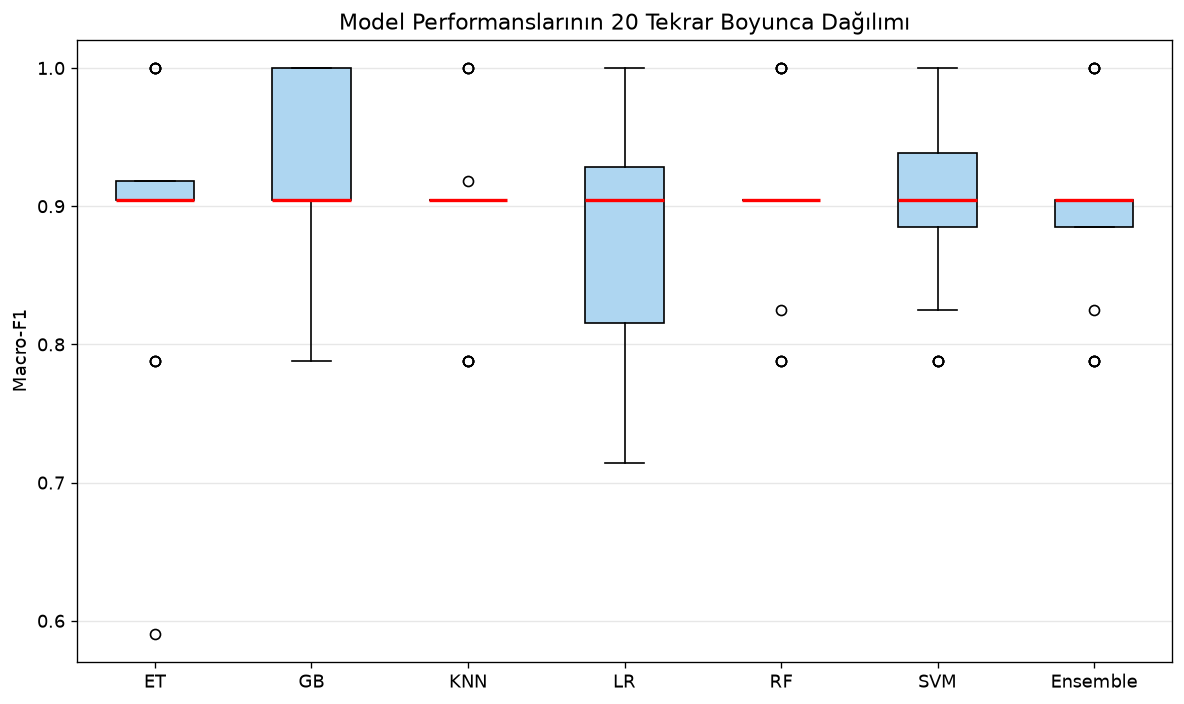

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = []
labels = []
for _, row in best_strategy_per_model.iterrows():
    name  = row["model"]
    strat = row["strategy"]
    subset = results_df[(results_df["model"]==name) & (results_df["strategy"]==strat)]
    plot_data.append(subset["Macro-F1"].values)
    labels.append(name)

# Ensemble ekle
ens_data = ens_df[ens_df["strategy"]==best_ens_strat]["Macro-F1"].values
plot_data.append(ens_data)
labels.append("Ensemble")

ax.boxplot(plot_data, tick_labels=labels, patch_artist=True,
           boxprops=dict(facecolor="#AED6F1"),
           medianprops=dict(color="red", lw=2))
ax.set_ylabel("Macro-F1")
ax.set_title("Model Performanslarının 20 Tekrar Boyunca Dağılımı")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("boxplot_models.png", dpi=150)
plt.show()

In [43]:
# ============================================================
# ADIM 5B: ENSEMBLE MODEL (RF + ET + GB — Soft Voting)
# Aynı 20 tekrar bölmeleri kullanılarak değerlendirilir.
# ============================================================

ensemble_results = []

print("=" * 60)
print("ENSEMBLE MODEL (RF + ET + GB Soft Voting)")
print("=" * 60)

for repeat in range(N_REPEATS):
    # Aynı bölmeleri yeniden oluştur (aynı random_state)
    patient_info = (
        pd.DataFrame({"PatientIndex": groups, "label": y})
        .groupby("PatientIndex")["label"].first().reset_index()
    )
    patient_info.columns = ["PatientIndex", "label"]

    pat_trainval, pat_test = train_test_split(
        patient_info, test_size=0.20,
        random_state=repeat, stratify=patient_info["label"]
    )
    pat_train, pat_val = train_test_split(
        pat_trainval, test_size=0.125,
        random_state=repeat, stratify=pat_trainval["label"]
    )

    train_ids = set(pat_train["PatientIndex"])
    val_ids   = set(pat_val["PatientIndex"])
    test_ids  = set(pat_test["PatientIndex"])

    train_idx = groups[groups.isin(train_ids)].index
    val_idx   = groups[groups.isin(val_ids)].index
    test_idx  = groups[groups.isin(test_ids)].index

    X_train_raw = X_raw.loc[train_idx].reset_index(drop=True)
    X_val_raw   = X_raw.loc[val_idx].reset_index(drop=True)
    X_test_raw  = X_raw.loc[test_idx].reset_index(drop=True)

    y_train = y.loc[train_idx].reset_index(drop=True)
    y_val   = y.loc[val_idx].reset_index(drop=True)
    y_test  = y.loc[test_idx].reset_index(drop=True)

    g_train = groups.loc[train_idx].reset_index(drop=True)
    g_val   = groups.loc[val_idx].reset_index(drop=True)
    g_test  = groups.loc[test_idx].reset_index(drop=True)

    # Preprocessing + MRMR (train'e fit)
    X_train_p, X_val_p, _ = preprocess(X_train_raw, X_val_raw)
    mrmr_rank = mrmr_classif(X=X_train_p, y=y_train, K=K_MAX, show_progress=False)

    # Ensemble için sabit K=30 (orta değer)
    K_ENS = 30
    selected = mrmr_rank[:K_ENS]

    # Model A: train → val olasılıkları (eşik optimizasyonu için)
    X_tr_m  = X_train_p[selected]
    X_val_m = X_val_p[selected]

    rf_a  = CalibratedClassifierCV(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), method="sigmoid", cv=3)
    et_a  = CalibratedClassifierCV(ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),  method="sigmoid", cv=3)
    gb_a  = CalibratedClassifierCV(GradientBoostingClassifier(n_estimators=100, random_state=42),       method="sigmoid", cv=3)

    ensemble_a = VotingClassifier(
        estimators=[("RF", rf_a), ("ET", et_a), ("GB", gb_a)],
        voting="soft"
    )
    ensemble_a.fit(X_tr_m, y_train)
    val_prob_ens = ensemble_a.predict_proba(X_val_m)[:, 1]

    thresh_ens, _ = optimize_threshold(val_prob_ens, y_val.values)

    # Model B: train+val → test (final değerlendirme)
    X_tv_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
    y_tv     = pd.concat([y_train, y_val], ignore_index=True)

    X_tv_p, X_test_p, _ = preprocess(X_tv_raw, X_test_raw)
    tv_rank  = mrmr_classif(X=X_tv_p, y=y_tv, K=K_ENS, show_progress=False)
    X_tv_m   = X_tv_p[tv_rank]
    X_test_m = X_test_p[tv_rank]

    rf_b  = CalibratedClassifierCV(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), method="sigmoid", cv=3)
    et_b  = CalibratedClassifierCV(ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),  method="sigmoid", cv=3)
    gb_b  = CalibratedClassifierCV(GradientBoostingClassifier(n_estimators=100, random_state=42),       method="sigmoid", cv=3)

    ensemble_b = VotingClassifier(
        estimators=[("RF", rf_b), ("ET", et_b), ("GB", gb_b)],
        voting="soft"
    )
    ensemble_b.fit(X_tv_m, y_tv)
    y_prob_test = ensemble_b.predict_proba(X_test_m)[:, 1]

    # Hasta düzeyi agregasyon
    strategies, patient_true = aggregate_to_patient_level(
        y_prob_test, g_test.values, y_test.values
    )

    for strat_name, pat_probs in strategies.items():
        pids      = np.array(list(pat_probs.keys()))
        probs_arr = np.array([pat_probs[p] for p in pids])
        true_arr  = np.array([patient_true[p] for p in pids])
        pred_arr  = (probs_arr >= thresh_ens).astype(int)

        if len(np.unique(pred_arr)) < 2:
            continue

        pr_prec, pr_rec, _ = precision_recall_curve(true_arr, probs_arr)

        ensemble_results.append({
            "repeat"     : repeat + 1,
            "model"      : "Ensemble",
            "strategy"   : strat_name,
            "Accuracy"   : accuracy_score(true_arr, pred_arr),
            "Precision"  : precision_score(true_arr, pred_arr, average="macro"),
            "Recall"     : recall_score(true_arr, pred_arr, average="macro"),
            "F1-weighted": f1_score(true_arr, pred_arr, average="weighted"),
            "Macro-F1"   : f1_score(true_arr, pred_arr, average="macro"),
            "Bal-Acc"    : balanced_accuracy_score(true_arr, pred_arr),
            "ROC-AUC"    : roc_auc_score(true_arr, probs_arr),
            "PR-AUC"     : auc(pr_rec, pr_prec),
            "Brier"      : brier_score_loss(true_arr, probs_arr),
            "ECE-10"     : compute_ece(probs_arr, true_arr),
            "threshold"  : thresh_ens,
            "K"          : K_ENS,
        })

    print(f"Tekrar {repeat+1:2d}: eşik={thresh_ens:.2f}", end="  ")

ens_df = pd.DataFrame(ensemble_results)

# Ensemble en iyi strateji
ens_summary = ens_df.groupby("strategy")["Macro-F1"].mean()
best_ens_strat = ens_summary.idxmax()

print(f"\n\nEnsemble en iyi strateji: {best_ens_strat}")
print(f"Macro-F1 : {ens_summary[best_ens_strat]:.4f}")

ens_best = ens_df[ens_df["strategy"] == best_ens_strat]
print("\nEnsemble Özet (mean ± std):")
for m in ["Macro-F1","ROC-AUC","Accuracy","Bal-Acc","Brier","ECE-10"]:
    print(f"  {m:12s}: {ens_best[m].mean():.4f} ± {ens_best[m].std():.4f}")

# Tüm sonuçlara ekle
all_results_with_ens = all_results + ensemble_results
results_df_full = pd.DataFrame(all_results_with_ens)
print(f"\nToplam kayıt (ensemble dahil): {len(results_df_full)}")

ENSEMBLE MODEL (RF + ET + GB Soft Voting)
Tekrar  1: eşik=0.50  Tekrar  2: eşik=0.61  Tekrar  3: eşik=0.15  Tekrar  4: eşik=0.71  Tekrar  5: eşik=0.47  Tekrar  6: eşik=0.31  Tekrar  7: eşik=0.79  Tekrar  8: eşik=0.53  Tekrar  9: eşik=0.13  Tekrar 10: eşik=0.75  Tekrar 11: eşik=0.10  Tekrar 12: eşik=0.31  Tekrar 13: eşik=0.62  Tekrar 14: eşik=0.29  Tekrar 15: eşik=0.70  Tekrar 16: eşik=0.37  Tekrar 17: eşik=0.62  Tekrar 18: eşik=0.35  Tekrar 19: eşik=0.41  Tekrar 20: eşik=0.14  

Ensemble en iyi strateji: majority_vote
Macro-F1 : 0.8964

Ensemble Özet (mean ± std):
  Macro-F1    : 0.8964 ± 0.0710
  ROC-AUC     : 0.8725 ± 0.0819
  Accuracy    : 0.9250 ± 0.0490
  Bal-Acc     : 0.8725 ± 0.0819
  Brier       : 0.0750 ± 0.0490
  ECE-10      : 0.0714 ± 0.0463

Toplam kayıt (ensemble dahil): 974


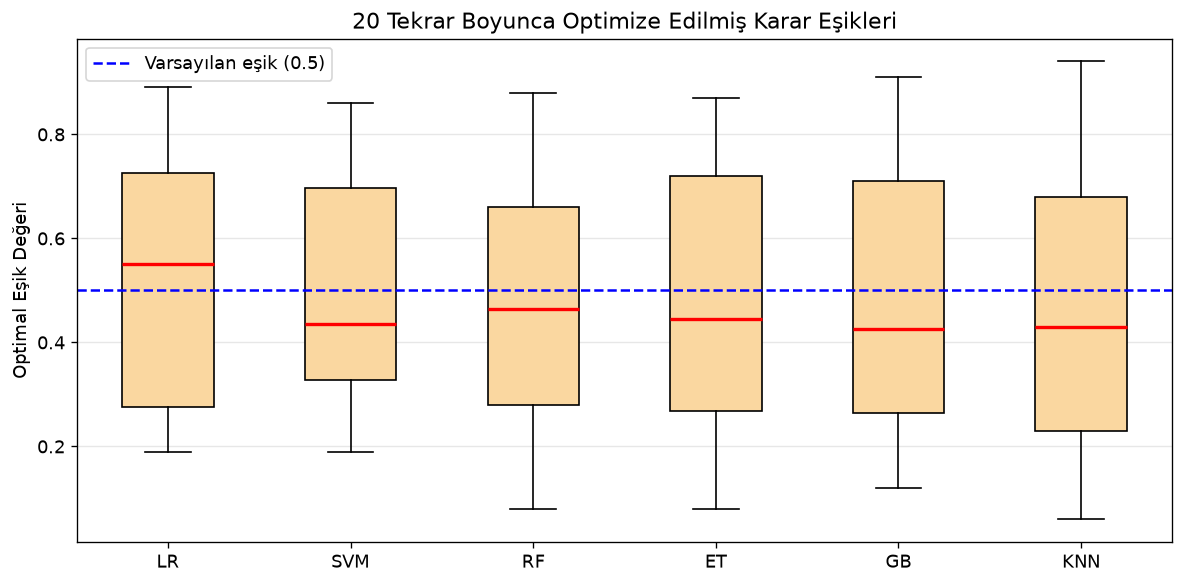

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))

thresh_data = {}
for name in MODEL_NAMES:
    thresh_data[name] = results_df[
        (results_df["model"] == name)
    ]["threshold"].values

ax.boxplot(thresh_data.values(), tick_labels=thresh_data.keys(), patch_artist=True,
           boxprops=dict(facecolor="#FAD7A0"),
           medianprops=dict(color="red", lw=2))
ax.axhline(0.5, color="blue", linestyle="--", lw=1.5, label="Varsayılan eşik (0.5)")
ax.set_ylabel("Optimal Eşik Değeri")
ax.set_title("20 Tekrar Boyunca Optimize Edilmiş Karar Eşikleri")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("threshold_distribution.png", dpi=150)
plt.show()

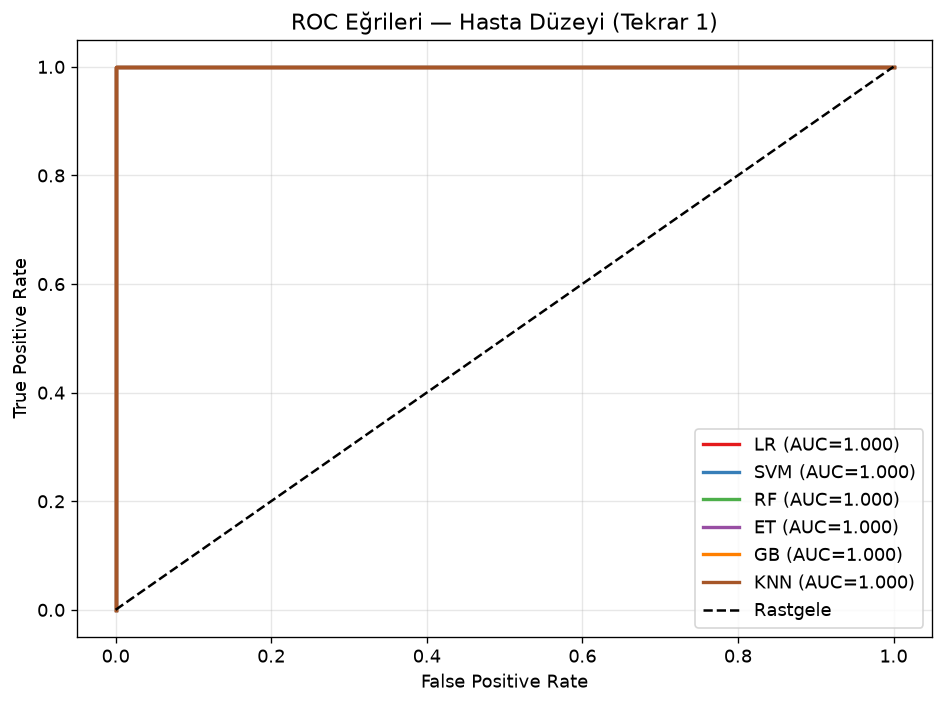

ROC Curve kaydedildi.


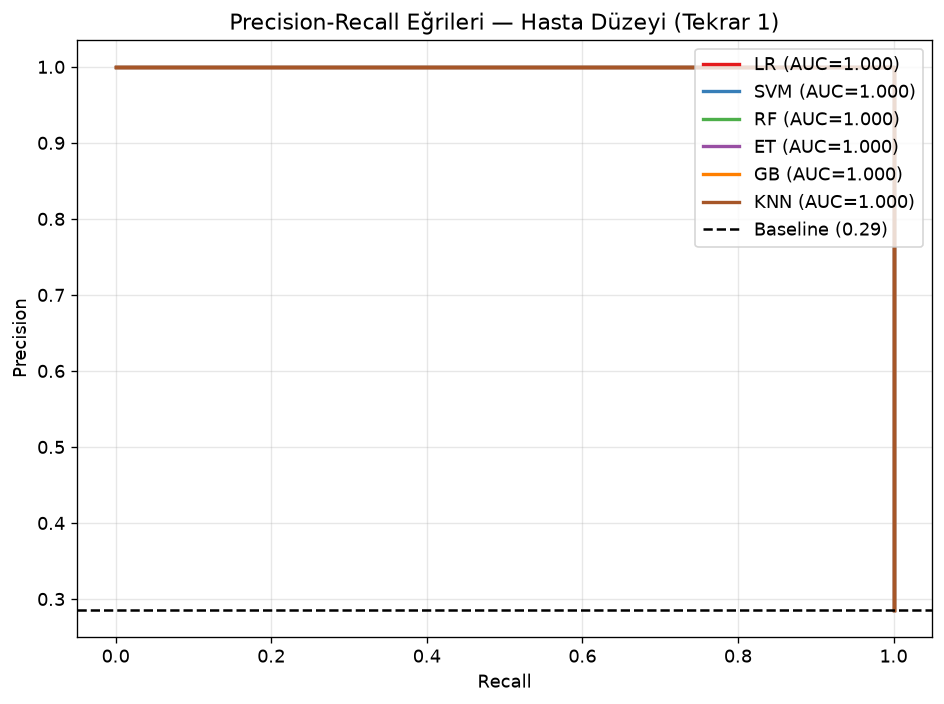

PR Curve kaydedildi.


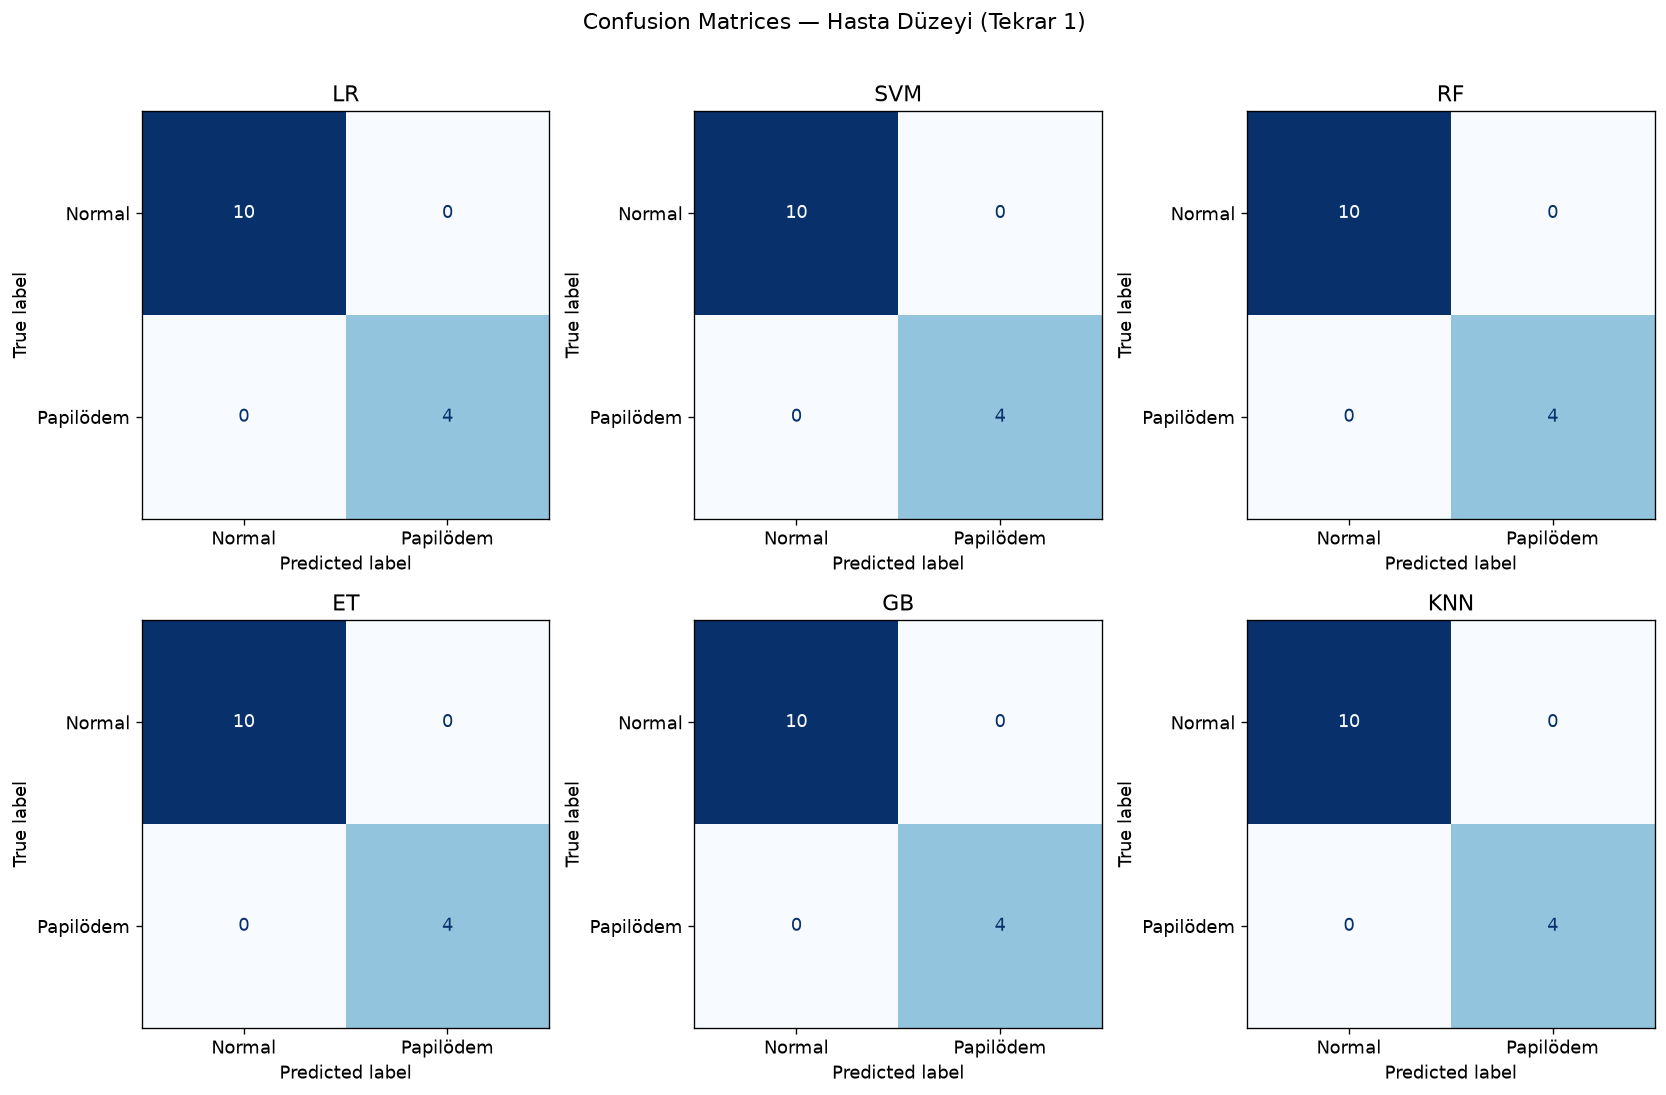

Confusion Matrix kaydedildi.


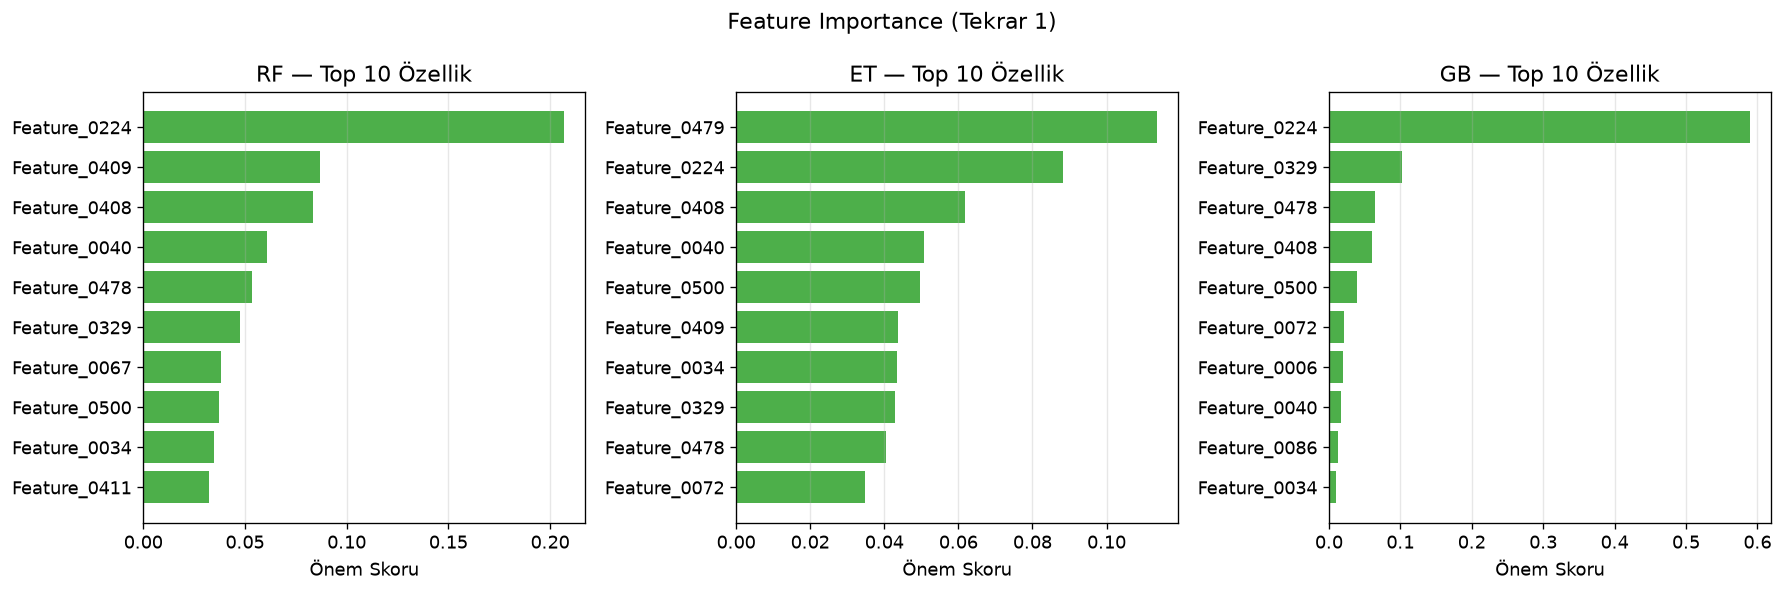

Feature Importance kaydedildi.


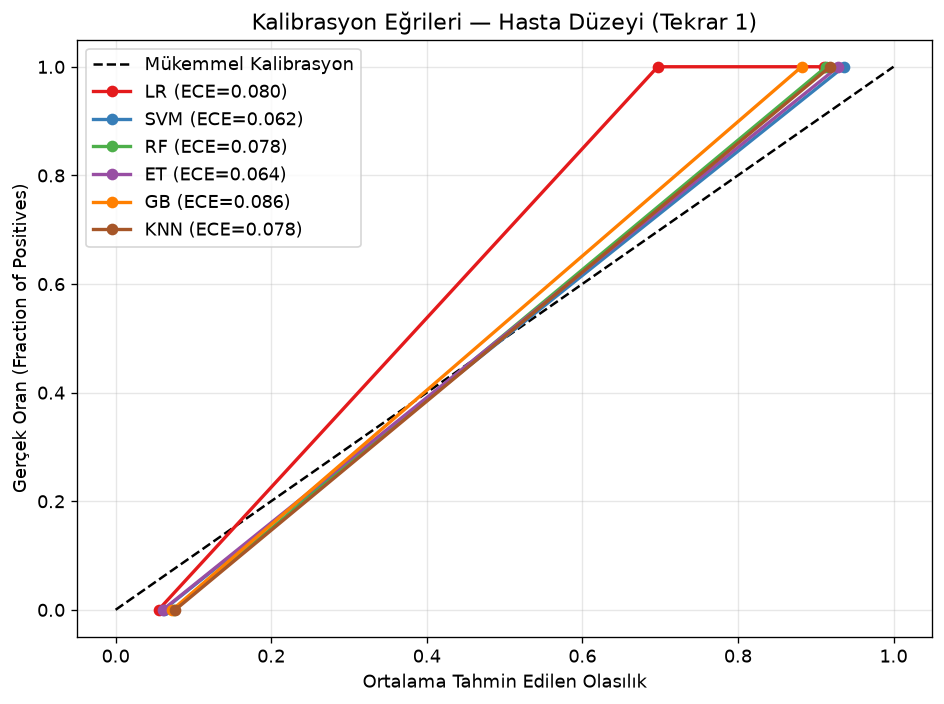

Calibration Curve kaydedildi.


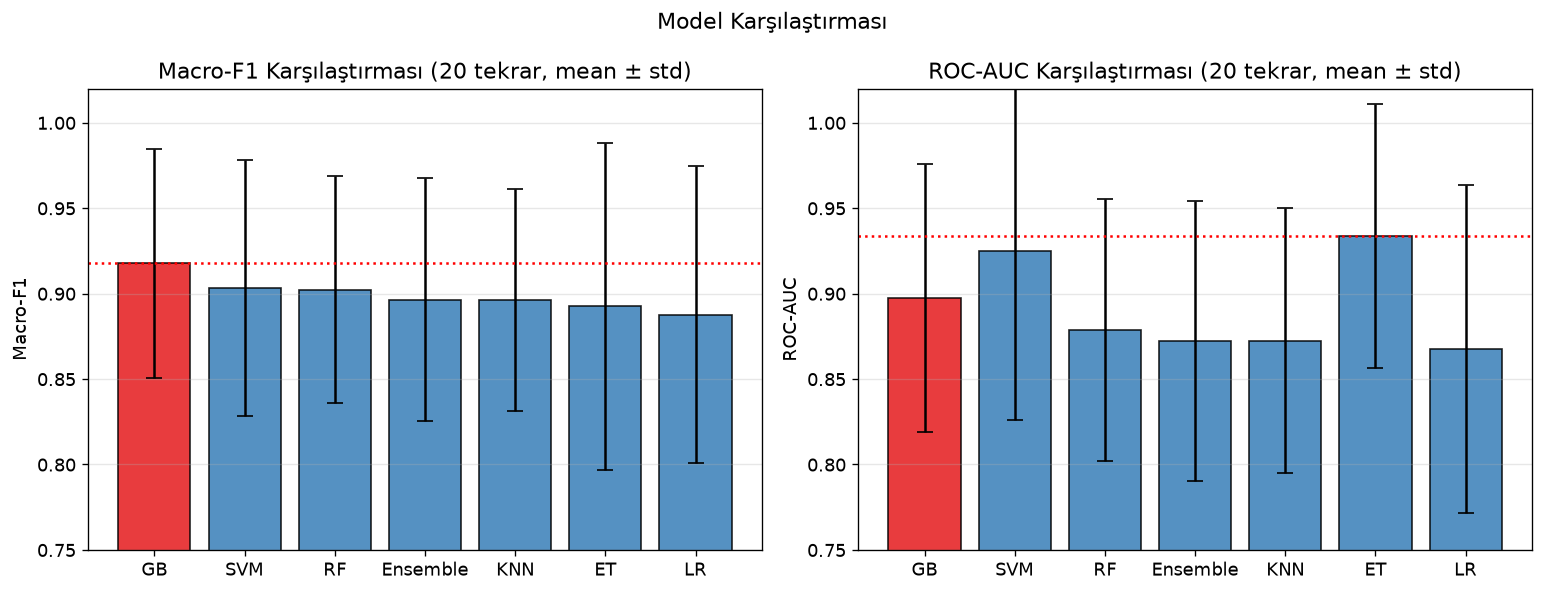

Model Karşılaştırma grafiği kaydedildi.


In [45]:
# ============================================================
# ADIM 6: GRAFİKLER VE GÖRSEL SONUÇLAR
# Görselleştirme için tekrar 0 kullanılır (temsili örnek)
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

# --- Tekrar 0 için verileri yeniden üret (görselleştirme için) ---
patient_info = (
    pd.DataFrame({"PatientIndex": groups, "label": y})
    .groupby("PatientIndex")["label"].first().reset_index()
)
patient_info.columns = ["PatientIndex", "label"]

pat_trainval, pat_test = train_test_split(
    patient_info, test_size=0.20, random_state=0, stratify=patient_info["label"]
)
pat_train, pat_val = train_test_split(
    pat_trainval, test_size=0.125, random_state=0, stratify=pat_trainval["label"]
)

train_ids = set(pat_train["PatientIndex"])
val_ids   = set(pat_val["PatientIndex"])
test_ids  = set(pat_test["PatientIndex"])

train_idx = groups[groups.isin(train_ids)].index
val_idx   = groups[groups.isin(val_ids)].index
test_idx  = groups[groups.isin(test_ids)].index

X_train_raw = X_raw.loc[train_idx].reset_index(drop=True)
X_val_raw   = X_raw.loc[val_idx].reset_index(drop=True)
X_test_raw  = X_raw.loc[test_idx].reset_index(drop=True)
y_train = y.loc[train_idx].reset_index(drop=True)
y_val   = y.loc[val_idx].reset_index(drop=True)
y_test  = y.loc[test_idx].reset_index(drop=True)
g_train = groups.loc[train_idx].reset_index(drop=True)
g_val   = groups.loc[val_idx].reset_index(drop=True)
g_test  = groups.loc[test_idx].reset_index(drop=True)

X_train_p, X_val_p, _ = preprocess(X_train_raw, X_val_raw)
mrmr_rank_viz = mrmr_classif(X=X_train_p, y=y_train, K=K_MAX, show_progress=False)

# Her model için train+val → test modeli kur
X_tv_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
y_tv     = pd.concat([y_train, y_val], ignore_index=True)

viz_models     = {}   # kalibre edilmiş modeller
viz_probs      = {}   # test olasılıkları (örnek düzeyi)
viz_pat_probs  = {}   # hasta düzeyi olasılıklar
viz_pat_true   = {}   # hasta düzeyi gerçek etiketler
viz_importances= {}   # özellik önemleri (RF, ET, GB için)

for name in MODEL_NAMES:
    # Sabit K=30 (görselleştirme için)
    K_viz = 30
    selected = mrmr_rank_viz[:K_viz]

    X_tv_p, X_test_p, _ = preprocess(X_tv_raw, X_test_raw)
    tv_rank   = mrmr_classif(X=X_tv_p, y=y_tv, K=K_viz, show_progress=False)
    X_tv_m    = X_tv_p[tv_rank]
    X_test_m  = X_test_p[tv_rank]

    base_model = build_model(name, {"K": K_viz})
    base_model.fit(X_tv_m, y_tv)

    # Feature importance (RF, ET, GB)
    if hasattr(base_model, "feature_importances_"):
        viz_importances[name] = pd.Series(
            base_model.feature_importances_, index=tv_rank
        ).sort_values(ascending=False).head(10)

    cal_model = CalibratedClassifierCV(base_model, method="sigmoid", cv=None)
    cal_model.fit(X_tv_m, y_tv)
    viz_models[name] = cal_model

    y_prob = cal_model.predict_proba(X_test_m)[:, 1]
    viz_probs[name] = y_prob

    strategies, patient_true = aggregate_to_patient_level(
        y_prob, g_test.values, y_test.values
    )
    viz_pat_probs[name] = np.array([strategies["mean"][p] for p in sorted(patient_true.keys())])
    viz_pat_true[name]  = np.array([patient_true[p] for p in sorted(patient_true.keys())])

pat_true_arr = viz_pat_true["LR"]   # tüm modeller için aynı hastalar

# ============================================================
# GRAFİK 1: ROC CURVE
# ============================================================
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#e41a1c","#377eb8","#4daf4a","#984ea3","#ff7f00","#a65628"]

for (name, col) in zip(MODEL_NAMES, colors):
    fpr, tpr, _ = roc_curve(viz_pat_true[name], viz_pat_probs[name])
    auc_val = roc_auc_score(viz_pat_true[name], viz_pat_probs[name])
    ax.plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC={auc_val:.3f})")

ax.plot([0,1],[0,1], "k--", lw=1.5, label="Rastgele")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Eğrileri — Hasta Düzeyi (Tekrar 1)")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("roc_curve.png", dpi=150); plt.show()
print("ROC Curve kaydedildi.")

# ============================================================
# GRAFİK 2: PRECISION-RECALL CURVE
# ============================================================
fig, ax = plt.subplots(figsize=(8, 6))

for (name, col) in zip(MODEL_NAMES, colors):
    prec, rec, _ = precision_recall_curve(viz_pat_true[name], viz_pat_probs[name])
    pr_auc = auc(rec, prec)
    ax.plot(rec, prec, color=col, lw=2, label=f"{name} (AUC={pr_auc:.3f})")

baseline = pat_true_arr.mean()
ax.axhline(baseline, color="k", linestyle="--", lw=1.5, label=f"Baseline ({baseline:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Eğrileri — Hasta Düzeyi (Tekrar 1)")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("pr_curve.png", dpi=150); plt.show()
print("PR Curve kaydedildi.")

# ============================================================
# GRAFİK 3: CONFUSION MATRIX (6 model yan yana)
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.flatten()

for i, name in enumerate(MODEL_NAMES):
    thresh = 0.5
    y_pred = (viz_pat_probs[name] >= thresh).astype(int)
    cm = confusion_matrix(viz_pat_true[name], y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Papilödem"])
    disp.plot(ax=axes[i], colorbar=False, cmap="Blues")
    axes[i].set_title(f"{name}")

fig.suptitle("Confusion Matrices — Hasta Düzeyi (Tekrar 1)", fontsize=13, y=1.01)
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print("Confusion Matrix kaydedildi.")

# ============================================================
# GRAFİK 4: FEATURE IMPORTANCE (RF, ET, GB — Top 10)
# ============================================================
imp_models = [n for n in ["RF","ET","GB"] if n in viz_importances]
fig, axes = plt.subplots(1, len(imp_models), figsize=(5*len(imp_models), 5))
if len(imp_models) == 1:
    axes = [axes]

for ax, name in zip(axes, imp_models):
    imp = viz_importances[name]
    ax.barh(imp.index[::-1], imp.values[::-1], color="#4daf4a")
    ax.set_xlabel("Önem Skoru")
    ax.set_title(f"{name} — Top 10 Özellik")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Feature Importance (Tekrar 1)", fontsize=13)
plt.tight_layout(); plt.savefig("feature_importance.png", dpi=150); plt.show()
print("Feature Importance kaydedildi.")

# ============================================================
# GRAFİK 5: CALIBRATION CURVE
# ============================================================
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0,1],[0,1], "k--", lw=1.5, label="Mükemmel Kalibrasyon")

for (name, col) in zip(MODEL_NAMES, colors):
    if len(viz_pat_probs[name]) < 5:
        continue
    prob_true, prob_pred = calibration_curve(
        viz_pat_true[name], viz_pat_probs[name], n_bins=5, strategy="uniform"
    )
    ece = compute_ece(viz_pat_probs[name], viz_pat_true[name])
    ax.plot(prob_pred, prob_true, "o-", color=col, lw=2,
            label=f"{name} (ECE={ece:.3f})")

ax.set_xlabel("Ortalama Tahmin Edilen Olasılık")
ax.set_ylabel("Gerçek Oran (Fraction of Positives)")
ax.set_title("Kalibrasyon Eğrileri — Hasta Düzeyi (Tekrar 1)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("calibration_curve.png", dpi=150); plt.show()
print("Calibration Curve kaydedildi.")

# ============================================================
# GRAFİK 6: MODEL KARŞILAŞTIRMA (20 tekrar ortalaması)
# ============================================================
compare_data = []
for _, row in best_strategy_per_model.iterrows():
    name  = row["model"]
    strat = row["strategy"]
    subset = results_df[(results_df["model"]==name) & (results_df["strategy"]==strat)]
    compare_data.append({
        "Model"   : name,
        "Macro-F1": subset["Macro-F1"].mean(),
        "F1_std"  : subset["Macro-F1"].std(),
        "ROC-AUC" : subset["ROC-AUC"].mean(),
        "AUC_std" : subset["ROC-AUC"].std(),
    })

# Ensemble ekle
ens_best_df = ens_df[ens_df["strategy"] == best_ens_strat]
compare_data.append({
    "Model"   : "Ensemble",
    "Macro-F1": ens_best_df["Macro-F1"].mean(),
    "F1_std"  : ens_best_df["Macro-F1"].std(),
    "ROC-AUC" : ens_best_df["ROC-AUC"].mean(),
    "AUC_std" : ens_best_df["ROC-AUC"].std(),
})

cmp_df = pd.DataFrame(compare_data).sort_values("Macro-F1", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bar_colors = ["#e41a1c" if m=="GB" else "#377eb8" for m in cmp_df["Model"]]

axes[0].bar(cmp_df["Model"], cmp_df["Macro-F1"],
            yerr=cmp_df["F1_std"], capsize=5,
            color=bar_colors, edgecolor="black", alpha=0.85)
axes[0].set_ylim(0.75, 1.02)
axes[0].set_ylabel("Macro-F1")
axes[0].set_title("Macro-F1 Karşılaştırması (20 tekrar, mean ± std)")
axes[0].axhline(cmp_df["Macro-F1"].max(), color="red", linestyle=":", lw=1.5)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(cmp_df["Model"], cmp_df["ROC-AUC"],
            yerr=cmp_df["AUC_std"], capsize=5,
            color=bar_colors, edgecolor="black", alpha=0.85)
axes[1].set_ylim(0.75, 1.02)
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("ROC-AUC Karşılaştırması (20 tekrar, mean ± std)")
axes[1].axhline(cmp_df["ROC-AUC"].max(), color="red", linestyle=":", lw=1.5)
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Model Karşılaştırması", fontsize=13)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()
print("Model Karşılaştırma grafiği kaydedildi.")

Kullanılan modeller: ['ET', 'GB', 'KNN', 'LR', 'RF', 'SVM', 'Ensemble']
Tekrar sayısı: 20

FRIEDMAN TESTİ
İstatistik : 9.4891
p-değeri   : 0.1479
Sonuç      : Modeller arasında anlamlı fark YOK (p >= 0.05)

WİLCOXON SIGNED-RANK TESTİ + BONFERRONİ DÜZELTMESİ
Toplam karşılaştırma: 21 çift → Bonferroni α = 0.05/21 = 0.0024
Model 1  Model 2  W-stat  p-raw  p-Bonferroni Ham sig Bonf sig
     ET       GB     3.0 0.0620        1.0000       ✗        ✗
     ET      KNN     5.0 0.4922        1.0000       ✗        ✗
     ET       LR    14.0 0.5745        1.0000       ✗        ✗
     ET       RF    10.0 0.9156        1.0000       ✗        ✗
     ET      SVM     3.5 0.2785        1.0000       ✗        ✗
     ET Ensemble     5.0 0.4922        1.0000       ✗        ✗
     GB      KNN     1.0 0.0452        0.9492       ✓        ✗
     GB       LR     3.0 0.0339        0.7118       ✓        ✗
     GB       RF     1.5 0.1025        1.0000       ✗        ✗
     GB      SVM    14.5 0.3403        1.0000   

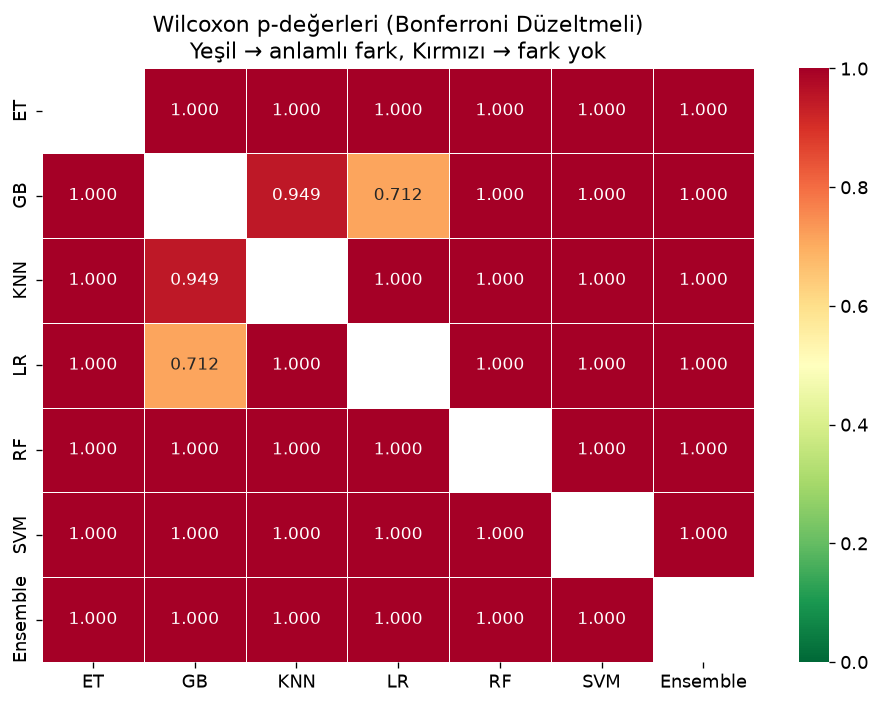

Wilcoxon ısı haritası kaydedildi.


In [46]:
# ============================================================
# ADIM 7: İSTATİSTİKSEL ANALİZ
# Friedman Test + Wilcoxon Signed-Rank + Bonferroni Düzeltmesi
# ============================================================

from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations

# Her model için en iyi strateji ile 20 tekrar Macro-F1 skorlarını topla
model_scores = {}
for _, row in best_strategy_per_model.iterrows():
    name  = row["model"]
    strat = row["strategy"]
    subset = results_df[(results_df["model"] == name) & (results_df["strategy"] == strat)]
    # Tekrar sırasına göre sırala
    scores = subset.sort_values("repeat")["Macro-F1"].values
    model_scores[name] = scores

# Ensemble ekle
ens_scores = ens_df[ens_df["strategy"] == best_ens_strat].sort_values("repeat")["Macro-F1"].values
model_scores["Ensemble"] = ens_scores

model_names_stat = list(model_scores.keys())
print("Kullanılan modeller:", model_names_stat)
print("Tekrar sayısı:", len(list(model_scores.values())[0]))

# ============================================================
# TEST 1: FRIEDMAN TESTİ
# Tüm modellerin performansları arasında anlamlı fark var mı?
# H0: Tüm modeller eşit performans gösterir
# ============================================================

print("\n" + "=" * 60)
print("FRIEDMAN TESTİ")
print("=" * 60)

score_arrays = [model_scores[n] for n in model_names_stat]
stat, p_friedman = friedmanchisquare(*score_arrays)

print(f"İstatistik : {stat:.4f}")
print(f"p-değeri   : {p_friedman:.4f}")
if p_friedman < 0.05:
    print("Sonuç      : Modeller arasında istatistiksel olarak ANLAMLI fark var (p < 0.05)")
else:
    print("Sonuç      : Modeller arasında anlamlı fark YOK (p >= 0.05)")

# ============================================================
# TEST 2: WİLCOXON SIGNED-RANK + BONFERRONİ DÜZELTMESİ
# Her model çifti için ikili karşılaştırma
# Bonferroni: p_adjusted = p_raw × karşılaştırma sayısı
# ============================================================

pairs    = list(combinations(model_names_stat, 2))
n_pairs  = len(pairs)

print(f"\n{'='*60}")
print(f"WİLCOXON SIGNED-RANK TESTİ + BONFERRONİ DÜZELTMESİ")
print(f"Toplam karşılaştırma: {n_pairs} çift → Bonferroni α = 0.05/{n_pairs} = {0.05/n_pairs:.4f}")
print(f"{'='*60}")

wilcoxon_results = []
for (m1, m2) in pairs:
    s1 = model_scores[m1]
    s2 = model_scores[m2]
    try:
        stat_w, p_raw = wilcoxon(s1, s2, zero_method="wilcox", alternative="two-sided")
    except ValueError:
        # Tüm farklar sıfırsa test yapılamaz
        stat_w, p_raw = 0.0, 1.0

    p_bonf    = min(p_raw * n_pairs, 1.0)   # Bonferroni düzeltmesi
    sig_raw   = "✓" if p_raw  < 0.05 else "✗"
    sig_bonf  = "✓" if p_bonf < 0.05 else "✗"

    wilcoxon_results.append({
        "Model 1"    : m1,
        "Model 2"    : m2,
        "W-stat"     : round(stat_w, 3),
        "p-raw"      : round(p_raw, 4),
        "p-Bonferroni": round(p_bonf, 4),
        "Ham sig"    : sig_raw,
        "Bonf sig"   : sig_bonf,
    })

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print(wilcoxon_df.to_string(index=False))

# ============================================================
# ÖZET: Kaç çift anlamlı fark gösteriyor?
# ============================================================

n_sig_raw  = (wilcoxon_df["p-raw"]        < 0.05).sum()
n_sig_bonf = (wilcoxon_df["p-Bonferroni"] < 0.05).sum()

print(f"\nHam p<0.05       : {n_sig_raw}/{n_pairs} çift anlamlı")
print(f"Bonferroni p<0.05: {n_sig_bonf}/{n_pairs} çift anlamlı")

# ============================================================
# GRAFİK: Wilcoxon p-değerleri ısı haritası
# ============================================================

import numpy as np

model_list = model_names_stat
n = len(model_list)
p_matrix = pd.DataFrame(np.ones((n, n)), index=model_list, columns=model_list)

for _, row in wilcoxon_df.iterrows():
    m1, m2 = row["Model 1"], row["Model 2"]
    p_matrix.loc[m1, m2] = row["p-Bonferroni"]
    p_matrix.loc[m2, m1] = row["p-Bonferroni"]

p_arr = p_matrix.values.copy().astype(float)
np.fill_diagonal(p_arr, 1.0)

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.eye(n, dtype=bool)
sns.heatmap(
    p_arr, annot=True, fmt=".3f",
    xticklabels=model_list, yticklabels=model_list,
    cmap="RdYlGn_r", vmin=0, vmax=1,
    linewidths=0.5, ax=ax, mask=mask,
    annot_kws={"size": 10}
)
ax.set_title("Wilcoxon p-değerleri (Bonferroni Düzeltmeli)\nYeşil → anlamlı fark, Kırmızı → fark yok")
plt.tight_layout()
plt.savefig("wilcoxon_heatmap.png", dpi=150)
plt.show()
print("Wilcoxon ısı haritası kaydedildi.")

BONUS 1: FEATURE STABILITY ANALİZİ
  LR | ≥50% tekrarda seçilen özellik: 33
  LR | ≥60% tekrarda seçilen özellik: 27
  LR | ≥70% tekrarda seçilen özellik: 19
  LR | ≥80% tekrarda seçilen özellik: 11

  SVM | ≥50% tekrarda seçilen özellik: 37
  SVM | ≥60% tekrarda seçilen özellik: 35
  SVM | ≥70% tekrarda seçilen özellik: 32
  SVM | ≥80% tekrarda seçilen özellik: 24

  RF | ≥50% tekrarda seçilen özellik: 30
  RF | ≥60% tekrarda seçilen özellik: 22
  RF | ≥70% tekrarda seçilen özellik: 17
  RF | ≥80% tekrarda seçilen özellik: 7

  ET | ≥50% tekrarda seçilen özellik: 35
  ET | ≥60% tekrarda seçilen özellik: 32
  ET | ≥70% tekrarda seçilen özellik: 28
  ET | ≥80% tekrarda seçilen özellik: 24

  GB | ≥50% tekrarda seçilen özellik: 20
  GB | ≥60% tekrarda seçilen özellik: 19
  GB | ≥70% tekrarda seçilen özellik: 19
  GB | ≥80% tekrarda seçilen özellik: 10

  KNN | ≥50% tekrarda seçilen özellik: 36
  KNN | ≥60% tekrarda seçilen özellik: 32
  KNN | ≥70% tekrarda seçilen özellik: 28
  KNN | ≥80

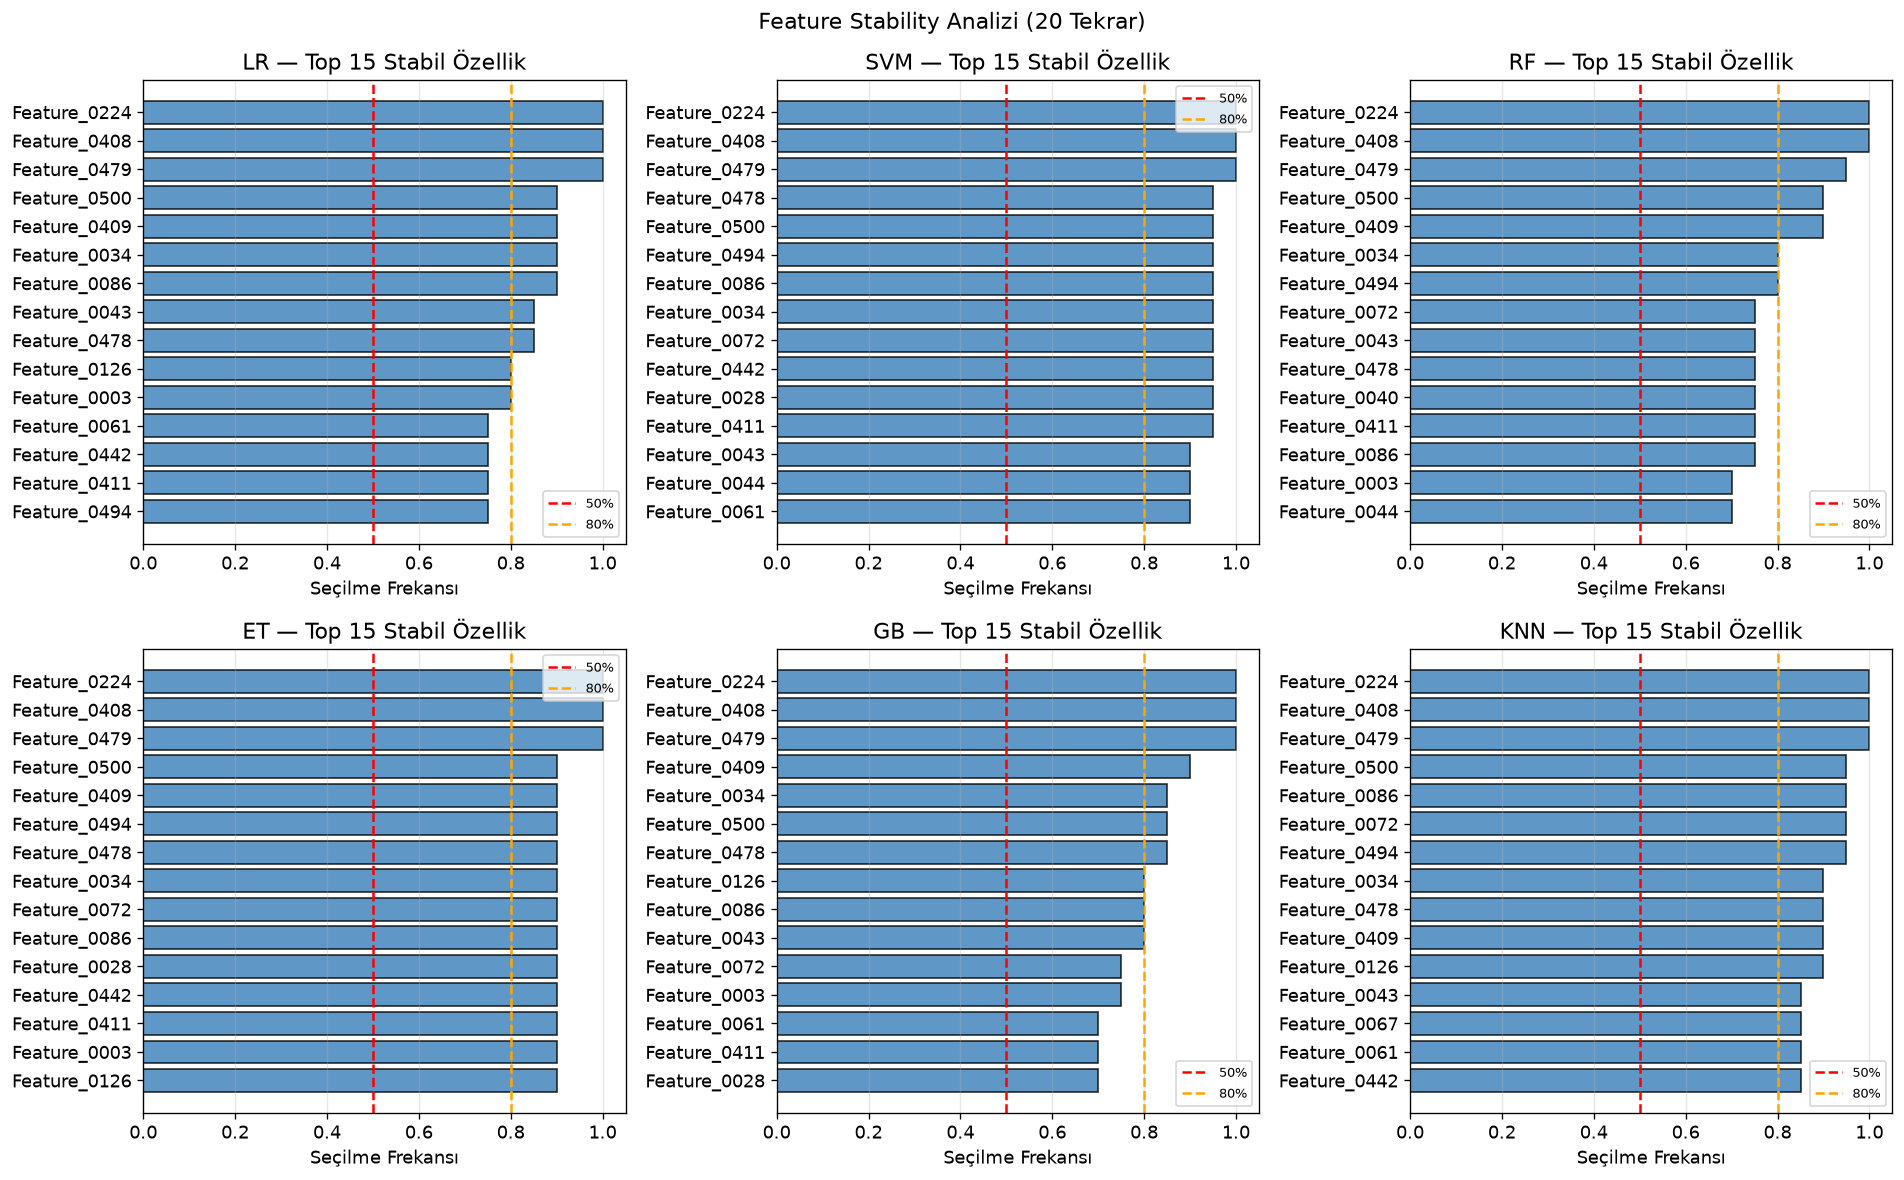

Feature Stability grafiği kaydedildi.


In [47]:
# ============================================================
# BONUS 1: FEATURE STABILITY ANALİZİ
# 20 tekrar boyunca hangi özellikler ne sıklıkla seçildi?
# ============================================================

print("=" * 60)
print("BONUS 1: FEATURE STABILITY ANALİZİ")
print("=" * 60)

stability_results = {}

for name in MODEL_NAMES:
    selections = feature_selection_log[name]  # 20 tekrar × seçilen özellikler
    if not selections:
        continue

    # Her özelliğin kaç tekrarda seçildiğini say
    from collections import Counter
    all_selected = [feat for repeat_feats in selections for feat in repeat_feats]
    counts = Counter(all_selected)
    total_repeats = len(selections)

    freq_df = pd.DataFrame({
        "feature"  : list(counts.keys()),
        "count"    : list(counts.values()),
        "frequency": [c / total_repeats for c in counts.values()]
    }).sort_values("frequency", ascending=False)

    stability_results[name] = freq_df

    # Eşik analizi: %50, %60, %70, %80 üzerinde seçilen özellik sayısı
    for thresh in [0.5, 0.6, 0.7, 0.8]:
        n_stable = (freq_df["frequency"] >= thresh).sum()
        print(f"  {name} | ≥{int(thresh*100)}% tekrarda seçilen özellik: {n_stable}")
    print()

# Görselleştirme: Her model için top-15 en stabil özellik
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, name in enumerate(MODEL_NAMES):
    if name not in stability_results:
        continue
    top15 = stability_results[name].head(15)
    axes[i].barh(top15["feature"][::-1], top15["frequency"][::-1],
                 color="#377eb8", edgecolor="black", alpha=0.8)
    axes[i].axvline(0.5, color="red",    linestyle="--", lw=1.5, label="50%")
    axes[i].axvline(0.8, color="orange", linestyle="--", lw=1.5, label="80%")
    axes[i].set_xlim(0, 1.05)
    axes[i].set_xlabel("Seçilme Frekansı")
    axes[i].set_title(f"{name} — Top 15 Stabil Özellik")
    axes[i].legend(fontsize=8)
    axes[i].grid(axis="x", alpha=0.3)

plt.suptitle("Feature Stability Analizi (20 Tekrar)", fontsize=13)
plt.tight_layout()
plt.savefig("feature_stability.png", dpi=150)
plt.show()
print("Feature Stability grafiği kaydedildi.")